```{contents}
:local:
:depth: 2
```

# 2.1 Nonlinear Programs and Convexity

:::{admonition} Draft status: first draft
:class: warning
First draft (2026-10-30), written from the course design notes. Not yet reviewed.
:::

```{admonition} Lectures
:class: tip
This topic accompanies these recorded lessons:

- Module 4, Lesson 1: *Nonlinear Programming Formulations*
- Module 4, Lesson 2: *Hessians and Eigenvalues*
- Module 4, Lesson 3: *Optimality Conditions and Convexity*
```

:::{admonition} Learning Objectives
:class: tip

By the end of this topic, you should be able to:

- Recognize a nonlinear program (NLP) and name the local and global solvers used for it.
- Write the electrolyzer dispatch with ohmic losses as an NLP in Pyomo and solve it.
- Compute the Hessian of a function and classify it by the signs of its eigenvalues.
- State the necessary and sufficient conditions for an unconstrained minimum in one and in $n$ dimensions.
- Test a function for convexity, and explain why "nonlinear" does not mean "non-convex".
:::

In the first module (Topics 1.1–1.5) we worked mostly with linear programs, where the solutions sit at vertices and a solver that finds a local optimum has also found the global one. In this topic we will turn the first dial of the nonlinear and mixed-integer topics and make the power of each stack grow faster than linearly with load (as it does when we include resistive heating), which turns the dispatch into a nonlinear program. However, nonlinearity alone is not what makes a problem hard. As we will see, the real difficulty in optimization comes from non-convexity, and we can test for it with the tools of this topic: the Hessian and its eigenvalues.

## Nonlinear programs

A **nonlinear program** (NLP) is an optimization problem with only continuous variables where at least one function (the objective or a constraint) is nonlinear. Almost every detailed model of a chemical process is nonlinear. For example, reaction rates are exponential in temperature, phase equilibria involve logarithms of compositions, and flowsheets with recycle streams multiply flows by concentrations. Parameter estimation for nonlinear models, constrained regression, portfolio selection (where the risk of a portfolio is a quadratic function of the amounts invested), and optimization problems containing a trained machine-learning model are also NLPs. Unlike in an LP, the optimum of an NLP need not sit at a vertex, since the feasible region can have curved boundaries and the optimum can be anywhere on the boundary or inside the feasible region.

There are two kinds of NLPs. In a **convex** NLP every local minimum is a global minimum, exactly as in an LP, so we can trust local solvers. In a **non-convex** NLP there can be several local minima, and a local solver will stop at whichever one it reaches first, so finding the global minimum and proving it requires a global solver, which is far more expensive. One convex class is common enough to have its own name: a **quadratic program** (QP) has a quadratic objective and linear constraints. Convex QPs have enough structure that most LP and MILP solvers (HiGHS, Gurobi, CPLEX) can solve them directly, and the same codes can also handle a convex quadratic objective with integer variables. In this course we will use two kinds of solver through Pyomo:

- **Ipopt** (Interior Point OPTimizer) is a local solver. It follows the interior-point idea: it stays strictly inside the inequality constraints and approaches the boundary only in the limit.
- **Couenne**, and the commercial solver BARON that the lectures name, are global solvers. They use the spatial branch-and-bound method of {doc}`Topic2.6-Non-convex_Problems_and_Bounding`.

### The ohmic dispatch

The running example from Topic 1.1 has three electrolyzer stacks A, B and C sharing a hydrogen demand $D$. In Topics 1.4 and 1.5 each stack drew power in proportion to its load, and now we will add the simplest physical loss that grows with load, which is resistive (ohmic) heating and grows with the square of the current. In per-unit, a stack running at load $x$ draws

$$
P_i(x) = x + r_i x^2 ,
$$

where the first term is the ideal (reversible) power and $r_i$ measures how lossy the stack is. Stack B has the lowest resistance and stack C has the highest, with $r = (0.50, 0.35, 0.70)$ for A, B and C. We can now write the dispatch problem as

$$
\begin{aligned}
\min_{x_A, x_B, x_C} \quad & \sum_i \left(x_i + r_i x_i^2\right) \\
\text{s.t.} \quad & x_A + x_B + x_C = D \\
& 0 \le x_i \le 1 .
\end{aligned}
$$

The constraints are linear, and only the objective is nonlinear. We can write the model in Pyomo and solve it with Ipopt, and if Ipopt is not installed the cell falls back to scipy's SLSQP, which is a local gradient-based method. The helper `t2.get_solver` looks for the solver executable and returns `None` if it cannot find one.

In [1]:
%matplotlib inline
import sys
sys.path.insert(0, '..')
import numpy as np
import matplotlib.pyplot as plt
import pyomo.environ as pyo
from scipy.optimize import minimize
plt.style.use('../settings/plot_style.mplstyle')
from _lib import electrolyzer as el
from _lib import part2a_tools as t2

r = {c: el.R_OHMIC[c] for c in el.NAMES}
rv = np.array([r[c] for c in el.NAMES])
D = 1.2                                     # 240 kg H2/h

def ohmic_model(D):
    m = pyo.ConcreteModel()
    m.S = pyo.Set(initialize=el.NAMES)
    m.x = pyo.Var(m.S, bounds=(0, 1), initialize=D / 3)
    m.power = pyo.Objective(expr=sum(m.x[i] + r[i] * m.x[i] ** 2 for i in m.S))
    m.demand = pyo.Constraint(expr=sum(m.x[i] for i in m.S) == D)
    return m

ipopt = t2.get_solver('ipopt')
if ipopt is not None:
    m = ohmic_model(D)
    ipopt.solve(m)
    x = np.array([pyo.value(m.x[i]) for i in el.NAMES]); cost = pyo.value(m.power)
else:
    res = minimize(lambda z: np.sum(z + rv * z**2), x0=[D / 3] * 3, bounds=[(0, 1)] * 3,
                   constraints=[{'type': 'eq', 'fun': lambda z: z.sum() - D}], method='SLSQP')
    x, cost = res.x, res.fun

for c, xi in zip(el.NAMES, x):
    print(f"stack {c}: load {xi:.4f} = {el.to_kg_h(xi):5.1f} kg/h")
print(f"total power {cost:.5f} per-unit = {el.to_mw(cost):.2f} MW")

stack A: load 0.3818 =  76.4 kg/h
stack B: load 0.5455 = 109.1 kg/h
stack C: load 0.2727 =  54.5 kg/h
total power 1.42909 per-unit = 9.34 MW


We can see that in this answer every stack runs and none of them is at full load, which never happens in a linear dispatch. With linear power curves the cheapest stack ran flat out and the next one took the remainder, but with ohmic losses piling load onto one stack makes its losses grow quadratically, so it is cheaper to spread the load out. This means the best split is in the **interior** of the feasible region rather than at a vertex. The low-resistance stack B carries the most (109 kg/h), and the lossy stack C carries the least (55 kg/h).

:::{exercise}
:label: ex-t21-ohmic-demand

Re-solve the ohmic dispatch for demands $D = 0.3, 0.6, \ldots, 2.7$. Plot each stack's load against $D$. At what demand does the first stack reach full load, and which stack is it? What happens to the other two loads after that point?
:::

### A lecture example: residence time of a reactor

:::{admonition} Adapted from a course notebook
:class: note
Adapted from the course notebook `Module 4/Module 4 Example.ipynb` (MIT License, © 2022 Data-Driven PSE Lab @ChBE-GT). The notebook integrates the rate equations with Pyomo.DAE; here we use their closed-form solution.
:::

The NLP example in the lecture is a reactor making a product B from a reactant A by the series reaction A → B → C, where C is a less valuable by-product. The rate constants are $k_A = 0.5$ and $k_B = 0.1$ per minute, and the feed has $c_{A,0} = 2$ mol/L. The course notebook integrates the first-order rate equations over the residence time $\tau$ (as for a plug-flow reactor) and chooses $\tau$ to maximize the value of the outlet, $10\,c_B + 3\,c_C$ in dollars per liter. Since the kinetics are first order, the outlet concentrations have a closed form,

$$
c_A = c_{A,0} e^{-k_A \tau}, \qquad c_B = \frac{c_{A,0}\,k_A}{k_B - k_A}\left(e^{-k_A \tau} - e^{-k_B \tau}\right), \qquad c_C = c_{A,0} - c_A - c_B ,
$$

so this is a one-variable NLP with an exponential objective.

In [2]:
from scipy.optimize import minimize_scalar

kA, kB, cA0 = 0.5, 0.1, 2.0            # 1/min, 1/min, mol/L

def outlet(tau):
    cA = cA0 * np.exp(-kA * tau)
    cB = cA0 * kA / (kB - kA) * (np.exp(-kA * tau) - np.exp(-kB * tau))
    return cA, cB, cA0 - cA - cB

value = lambda tau: 10 * outlet(tau)[1] + 3 * outlet(tau)[2]      # $/L
res = minimize_scalar(lambda tau: -value(tau), bounds=(0, 30), method='bounded',
                      options={'xatol': 1e-10})
tau_opt = res.x
h = 1e-4
curv = (value(tau_opt + h) - 2 * value(tau_opt) + value(tau_opt - h)) / h**2
print(f"best residence time {tau_opt:.2f} min, outlet value {value(tau_opt):.3f} $/L "
      f"(at 5 min: {value(5.0):.3f} $/L)")
print(f"second derivative of the value at the optimum: {curv:.3f} $/(L min^2)")

best residence time 4.76 min, outlet value 14.697 $/L (at 5 min: 14.685 $/L)
second derivative of the value at the optimum: -0.435 $/(L min^2)


The best residence time is 4.76 minutes. This is a little shorter than a 5-minute design, because a shorter time leaves A unconverted while a longer one lets B decay into the cheaper C. The second derivative of the value at the optimum is negative, as it should be at a maximum, and in the next two sections we will make this check precise for any number of variables.

Most reactor models do not have a closed form, so the lecture solves this one the general way, and we will do the same here. Pyomo's `pyomo.dae` extension writes the rate equations as constraints on the concentration profiles and discretizes them by orthogonal collocation, which turns the differential equations into algebraic ones. There are two things to notice when we make the residence time a decision variable. First, if $\tau$ is fixed the model has no degrees of freedom, since every variable is determined by the equations, so \"solving\" it is really a simulation. Second, to let $\tau$ vary we need to rescale the time axis to a dimensionless $s = t/\tau \in [0, 1]$, and then each rate equation becomes $dc_i/ds = \tau \cdot r_i(c)$. The equations on this fixed horizon contain the products $\tau \cdot c_i$, which are bilinear, and these products are where the nonlinearity in the optimization comes from.

In [3]:
from pyomo.dae import ContinuousSet, DerivativeVar

def reactor_model(tau_fixed=None):
    m = pyo.ConcreteModel()
    m.s = ContinuousSet(bounds=(0, 1))                           # dimensionless time s = t / tau
    m.tau = pyo.Var(bounds=(0, 30), initialize=5.0)              # residence time, min
    if tau_fixed is not None:
        m.tau.fix(tau_fixed)                                     # zero degrees of freedom: a simulation
    m.c = pyo.Var(['A', 'B', 'C'], m.s, bounds=(0, None), initialize=0.5)
    m.dc = DerivativeVar(m.c, wrt=m.s)
    rate = {'A': lambda m, s: -kA * m.c['A', s],
            'B': lambda m, s: kA * m.c['A', s] - kB * m.c['B', s],
            'C': lambda m, s: kB * m.c['B', s]}
    m.ode = pyo.Constraint(['A', 'B', 'C'], m.s, rule=lambda m, i, s:
                           m.dc[i, s] == m.tau * rate[i](m, s) if s > 0 else pyo.Constraint.Skip)
    m.c['A', 0].fix(cA0); m.c['B', 0].fix(0); m.c['C', 0].fix(0)
    m.value = pyo.Objective(expr=10 * m.c['B', 1] + 3 * m.c['C', 1], sense=pyo.maximize)
    pyo.TransformationFactory('dae.collocation').apply_to(m, nfe=20, ncp=3)
    return m

if ipopt is not None:
    sim = reactor_model(tau_fixed=5.0); ipopt.solve(sim)
    print("simulation at 5 min: outlet c_A, c_B, c_C =",
          [round(pyo.value(sim.c[i, 1]), 2) for i in 'ABC'], " closed form:", [round(float(c), 2) for c in outlet(5.0)])
    opt = reactor_model(); ipopt.solve(opt)
    print(f"optimization: residence time {pyo.value(opt.tau):.2f} min, value {pyo.value(opt.value):.3f} $/L")
else:
    print("Ipopt not available; the closed-form result above is the answer.")

simulation at 5 min: outlet c_A, c_B, c_C = [0.16, 1.31, 0.52]  closed form: [0.16, 1.31, 0.52]


optimization: residence time 4.76 min, value 14.697 $/L


| Outlet at $\tau$ = 5 min (mol/L) | $c_A$ | $c_B$ | $c_C$ |
|---|---|---|---|
| Collocation (`pyomo.dae`) | 0.16 | 1.31 | 0.52 |
| Closed form | 0.16 | 1.31 | 0.52 |

| Optimum | Residence time (min) | Outlet value (\$/L) |
|---|---|---|
| Closed form (`minimize_scalar`) | 4.76 | 14.697 |
| Collocation (Ipopt) | 4.76 | 14.697 |

The collocation model reproduces the closed form. At 5 minutes it gives the same outlet concentrations, and the optimization returns the same residence time and outlet value as `minimize_scalar` did above.

:::{exercise}
:label: ex-t21-cstr-price

Change the by-product value from 3 to 8 $/L and re-solve. Explain the new optimum in words. Then plot `value(tau)` for $0 \le \tau \le 30$ for both prices: is the value a concave function of $\tau$ over the whole range?
:::

## Hessians and eigenvalues

For a function of one variable, the second derivative tells us how the function curves, and for a function of $n$ variables the curvature becomes a matrix. The **Hessian** of a twice-differentiable function $f(x_1, \ldots, x_n)$ is the $n \times n$ matrix of its second partial derivatives,

$$
H(x) = \nabla^2 f(x), \qquad H_{jk} = \frac{\partial^2 f}{\partial x_j \, \partial x_k} .
$$

Because the order of differentiation does not matter for smooth functions, $H$ is **symmetric**. A symmetric matrix has real eigenvalues, and their signs classify it:

| Eigenvalues of $H$ | Name | Shape of $f$ near the point | If this holds at every point, $f$ is |
|---|---|---|---|
| all $> 0$ | positive definite | a bowl, curving up in every direction | strictly convex |
| all $\ge 0$ | positive semidefinite (PSD) | a bowl or a trough, never curving down | convex |
| all $< 0$ | negative definite | a dome | strictly concave |
| all $\le 0$ | negative semidefinite | a dome or a ridge | concave |
| some $> 0$, some $< 0$ | indefinite | a saddle | neither (non-convex) |

The last column connects the Hessian to the definition of convexity in Topic 1.1. A strictly convex function has at most one minimizer, while a convex function that is not strictly convex can have a whole set of minimizers with the same value, as along the trough of a PSD Hessian. (A Hessian that is positive definite everywhere is sufficient for strict convexity but not necessary: $x^4$ is strictly convex although $f''(0) = 0$.)

The eigenvalues also have a direct geometric meaning: if $v$ is a unit eigenvector with eigenvalue $\lambda$, then $v^\top H v = \lambda$, so $\lambda$ is the curvature of $f$ along the direction $v$, which means that a function with a positive definite Hessian curves up along every direction while a function with an indefinite Hessian curves up along some directions and down along others.

**The ohmic fleet.** The total power $\sum_i (x_i + r_i x_i^2)$ is a sum of terms that each depend on only one variable, so its Hessian is the diagonal matrix $H = \mathrm{diag}(2 r_A, 2 r_B, 2 r_C)$ with eigenvalues $2r_i > 0$ at every point, and the power of the fleet is a bowl at every load.

**The S-curve fleet.** Topic 1.1 also introduced a power curve with a concave start-up term, $P(x) = x + a\,x/(x+\epsilon) + r x^2$, and for two stacks of type A the Hessian of $P(x_1) + P(x_2)$ is again diagonal with entries $P''(x_1)$ and $P''(x_2)$ from $P''(x) = 2r - 2a\epsilon/(x+\epsilon)^3$. At low load the negative term is larger than the positive one, so the curvature is negative in that region.

**The ideal mixture.** Chemical engineers meet Hessians most often in thermodynamics, and a good example of this is the Gibbs energy of mixing of an ideal mixture, which is given by

$$
G_{\mathrm{mix}}(n) = RT \sum_i n_i \ln \frac{n_i}{N}, \qquad N = \sum_j n_j ,
$$

Differentiating this twice gives the Hessian:

$$
H_{jk} = RT\left(\frac{\delta_{jk}}{n_j} - \frac{1}{N}\right).
$$

We can compute the eigenvalues of all three of these numerically:

In [4]:
def eig_report(name, H):
    lam = np.linalg.eigvalsh(H)
    tol = 1e-9 * max(1.0, np.abs(lam).max())
    kind = ('positive definite' if lam.min() > tol else
            'positive semidefinite' if lam.min() > -tol else
            'indefinite' if lam.max() > tol else 'negative semidefinite')
    print(f"{name:40s} eigenvalues {np.array2string(lam, precision=3)} -> {kind}")

eig_report("ohmic fleet (any loads)", np.diag(2 * rv))

a, rA, eps = el.A_PARASITIC['A'], el.R_OHMIC['A'], el.EPS
P2 = lambda x: 2 * rA - 2 * a * eps / (x + eps) ** 3
for pt in [(0.45, 0.45), (0.05, 0.85)]:
    eig_report(f"S-curve, two A stacks at {pt}", np.diag([P2(pt[0]), P2(pt[1])]))

RT = 8.314462618 * 298.15                       # J/mol
n = np.array([0.6, 0.3, 0.1])                   # mol of three ideal-gas species
H_mix = RT * (np.diag(1 / n) - 1 / n.sum())
eig_report("ideal-mixing Gibbs energy (J/mol^2)", H_mix)
print(f"H_mix @ n = {np.array2string(H_mix @ n, precision=2)}  (n itself is the zero eigenvector)")

ohmic fleet (any loads)                  eigenvalues [0.7 1.  1.4] -> positive definite
S-curve, two A stacks at (0.45, 0.45)    eigenvalues [0.76 0.76] -> positive definite
S-curve, two A stacks at (0.05, 0.85)    eigenvalues [-29.      0.959] -> indefinite
ideal-mixing Gibbs energy (J/mol^2)      eigenvalues [-1.267e-12  6.862e+03  2.289e+04] -> positive semidefinite
H_mix @ n = [-4.00e-13 -5.42e-13 -4.22e-13]  (n itself is the zero eigenvector)


| Function | Point | Eigenvalues | Classification |
|---|---|---|---|
| Ohmic fleet | any loads | 0.7, 1.0, 1.4 | positive definite |
| S-curve, two A stacks | (0.45, 0.45) | 0.76, 0.76 | positive definite |
| S-curve, two A stacks | (0.05, 0.85) | −29.0, 0.959 | indefinite |
| Ideal-mixing Gibbs energy (J/mol²) | $n = (0.6, 0.3, 0.1)$ | $-1.267 \times 10^{-12}$, $6.862 \times 10^{3}$, $2.289 \times 10^{4}$ | positive semidefinite |

The ohmic fleet is positive definite at every load, and the S-curve fleet is positive definite at the equal split but indefinite when one stack is lightly loaded, because that stack is in the concave start-up region where the power curves down along its axis. This negative curvature is what produces the second valley from Topic 1.1.

The ideal-mixing Hessian is positive semidefinite but not definite: one eigenvalue is zero (up to round-off), with the composition $n$ itself as its eigenvector. Scaling every amount by the same factor scales $G_{\mathrm{mix}}$ by that factor too, so along this direction the function is a straight line with zero curvature, while every other direction (i.e. any change in composition) curves up. This curvature is what made the closed-cell electrolysis of Topic 1.2 convex, as well as what keeps its minimum away from the boundary.

:::{exercise}
:label: ex-t21-hessian

For a stack of type A with the S-curve, find the range of loads over which $P''(x) < 0$ by solving $P''(x) = 0$. Then make a grid of points $(x_1, x_2)$ in $[0, 1]^2$ and color each point by whether the Hessian of $P(x_1) + P(x_2)$ there is positive definite or indefinite. Where is the "bowl" region?
:::

## Optimality conditions

Next we will use derivatives to recognize a minimum, starting with one variable. A point $x^*$ in the interior of the domain where $f$ is twice differentiable can only be a local minimum if

- **first-order necessary condition:** $f'(x^*) = 0$ (the point is **stationary**), and
- **second-order necessary condition:** $f''(x^*) \ge 0$.

All of these conditions assume that the derivatives exist, and functions with kinks such as $|x|$ or $\max(x, 0)$ have no derivative at the kink, which is one reason modelers reformulate them before handing them to a gradient-based solver (Topic 2.4 shows how). The conditions are also only necessary, since $f(x) = x^3$ satisfies both of them at $x = 0$ even though $x = 0$ is not a minimum. A **sufficient** condition for a strict local minimum is $f'(x^*) = 0$ together with $f''(x^*) > 0$ (for a maximum the inequalities are reversed), but a sufficient condition at one point can only prove a local minimum. If $f'' \ge 0$ holds at *every* point, the function is convex and any stationary point is a global minimum, whereas otherwise the other local minima and the end points of the domain also need to be checked.

In $n$ dimensions the same statements hold, with the gradient in place of $f'$ and the Hessian in place of $f''$:

- **First order (necessary):** $\nabla f(x^*) = 0$.
- **Second order (necessary):** $\nabla^2 f(x^*)$ is positive semidefinite.
- **Sufficient for a strict local minimum:** $\nabla f(x^*) = 0$ and $\nabla^2 f(x^*)$ is positive definite.

A stationary point with an indefinite Hessian is called a **saddle point**, since it is a minimum along some directions and a maximum along others. Numerical methods for finding stationary points, such as gradient descent and its relatives, are covered in DA4CHE Topic 1.4 (https://www.medford.chbe.gatech.edu/DA4CHE/), so we will not repeat them here.

### The dispatch as an unconstrained problem

The dispatch has a constraint, but we can remove it by **variable elimination**: the demand constraint fixes $x_C = D - x_A - x_B$, which leaves an unconstrained function of two variables,

$$
f(x_A, x_B) = P_A(x_A) + P_B(x_B) + P_C(D - x_A - x_B).
$$

For now we will ignore the bounds $0 \le x_i \le 1$ and check them at the end. Setting the gradient to zero gives

$$
\frac{\partial f}{\partial x_A} = P_A'(x_A) - P_C'(x_C) = 0, \qquad \frac{\partial f}{\partial x_B} = P_B'(x_B) - P_C'(x_C) = 0,
$$

so at the optimum the three **marginal powers** $P_i'(x_i) = 1 + 2 r_i x_i$ must be equal. We will call their common value $\lambda$. For the ohmic curves these conditions are linear in the loads, so we can solve $x_i = (\lambda - 1)/(2 r_i)$ together with $\sum_i x_i = D$ to get a closed form for $\lambda$:

$$
\lambda - 1 = \frac{D}{\sum_i 1/(2 r_i)} .
$$

The Hessian of $f$ is constant,

$$
\nabla^2 f = \begin{pmatrix} 2r_A + 2r_C & 2r_C \\ 2r_C & 2r_B + 2r_C \end{pmatrix},
$$

which is positive definite, so the stationary point is the global minimum of $f$.

In [5]:
rA, rB, rC = rv
H_elim = np.array([[2*rA + 2*rC, 2*rC], [2*rC, 2*rB + 2*rC]])

def stationary_point(D):
    lam = 1 + D / np.sum(1 / (2 * rv))
    return lam, (lam - 1) / (2 * rv)

lam, xs = stationary_point(1.2)
print(f"D = 1.2: lambda = {lam:.5f}, loads {np.round(xs, 4)}, "
      f"Hessian eigenvalues {np.round(np.linalg.eigvalsh(H_elim), 3)}")

def f_elim(z, D=1.2):
    loads = (z[0], z[1], D - z[0] - z[1])
    return sum(el.p_ohmic(v, c) for v, c in zip(loads, el.NAMES))

bfgs = minimize(f_elim, x0=[0.0, 0.0], method='BFGS')
print(f"BFGS from (0, 0): x_A = {bfgs.x[0]:.4f}, x_B = {bfgs.x[1]:.4f}, power {bfgs.fun:.5f}")

lam, xs = stationary_point(2.5)
print(f"D = 2.5: lambda = {lam:.5f}, loads {np.round(xs, 4)}; "
      f"bounds satisfied? {bool(np.all((xs >= 0) & (xs <= 1)))}")

D = 1.2: lambda = 1.38182, loads [0.3818 0.5455 0.2727], Hessian eigenvalues [0.842 3.658]
BFGS from (0, 0): x_A = 0.3818, x_B = 0.5455, power 1.42909
D = 2.5: lambda = 1.79545, loads [0.7955 1.1364 0.5682]; bounds satisfied? False


| $D = 1.2$ | $x_A$ | $x_B$ | $x_C$ | Power (per-unit) |
|---|---|---|---|---|
| Closed form, $\lambda = 1.38182$ | 0.3818 | 0.5455 | 0.2727 | – |
| BFGS from (0, 0) | 0.3818 | 0.5455 | – | 1.42909 |
| Ipopt (first cell) | 0.3818 | 0.5455 | 0.2727 | 1.42909 |

At $D = 1.2$ the closed form, BFGS (a quasi-Newton descent method, started here from the origin) and Ipopt all give $\lambda = 1.38182$ and the same loads. The eliminated problem is a convex bowl, so it does not matter where BFGS starts.

At $D = 2.5$, however, the same formula asks stack B to run at 1.1364, which is more than its capacity. Elimination removed the equality but not the bounds, and now one of the bounds limits the solution. Constraints that may or may not bind are handled by the KKT conditions in {doc}`Topic2.2-Lagrange_Multipliers_and_KKT_Conditions`, where the common marginal power $\lambda$ comes back as a Lagrange multiplier.

:::{exercise}
:label: ex-t21-saddle

Apply the same stationarity test to two stacks of type A with the S-curve and $D = 0.9$: write $f(x_1) = P(x_1) + P(0.9 - x_1)$, find all its stationary points on $[0, 0.9]$ numerically (for example with `scipy.optimize.brentq` on $f'$ over a fine set of brackets), and classify each by the sign of $f''$. How many local minima and local maxima are there?
:::

## Convexity

Remember that in Topic 1.1 we defined a convex function as one where the chord between any two points on its graph lies on or above the graph. For twice-differentiable functions there is an easier test: a function of one variable is convex on an interval if and only if $f''(x) \ge 0$ throughout the interval, and a function of $n$ variables is convex on a convex set if and only if its Hessian is positive semidefinite at every point of the set. The words "at every point" are important here, because a Hessian that is positive definite at the optimum only certifies a local minimum, while a Hessian that is PSD everywhere certifies convexity, which also means the local minimum is global.

Since checking the Hessian everywhere can be tedious, in practice we build convex functions from simpler ones using a few rules:

1. A sum of convex functions is convex. (The fleet's power is a sum of convex stack curves.)
2. A convex function times a nonnegative constant is convex.
3. A convex function of an affine expression, $f(Ax + b)$, is convex. (This is why eliminating $x_C = D - x_A - x_B$ kept the problem convex.)
4. If $f$ is convex and $g$ is convex and nondecreasing, then $g(f(x))$ is convex. For example, $e^{f(x)}$ is convex whenever $f$ is.
5. The pointwise maximum of convex functions is convex.

A function is **concave** if $-f$ is convex. Maximizing a concave function is the same as minimizing a convex function, so it is just as easy. In the figure below we show the three cases with one chord each, using the power curves of stack A: the ohmic curve is convex, the revenue curve of the next subsection is concave, and the S-curve is neither convex nor concave.

findfont: Failed to find font weight ultralight for Helvetica, now using 300.


findfont: Failed to find font weight ultralight for Helvetica, now using 300.


findfont: Failed to find font weight ultralight for Helvetica, now using 300.


findfont: Failed to find font weight ultralight for Helvetica, now using 300.


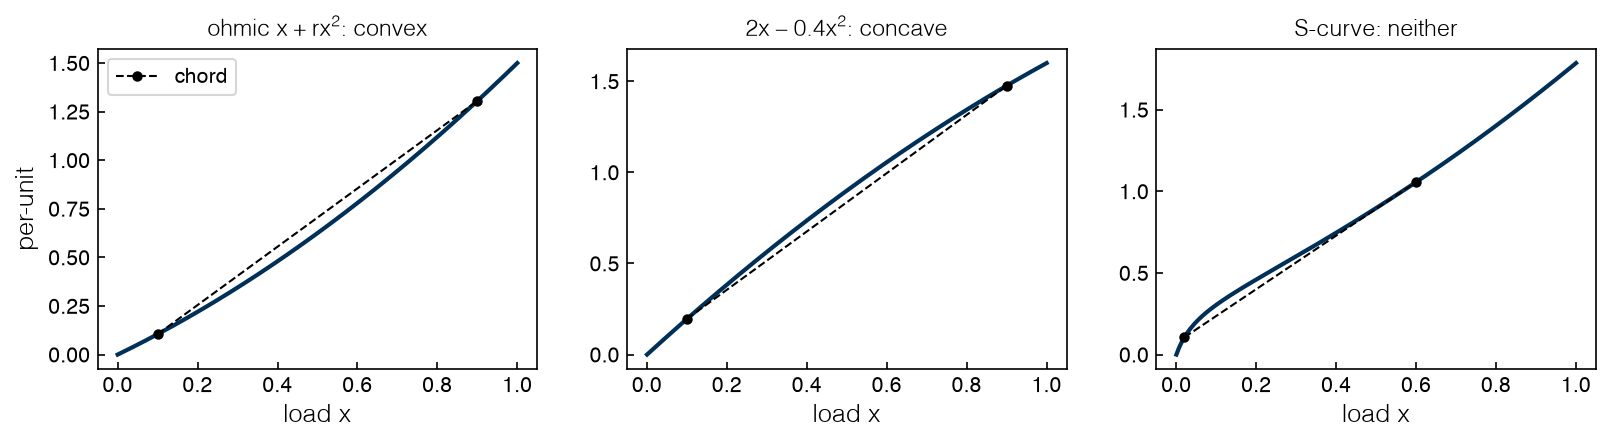

In [6]:
xx = np.linspace(0, 1, 200)
cases = [('ohmic $x + r x^2$: convex', el.p_ohmic(xx, 'A'), (0.1, 0.9)),
         ('$2x - 0.4x^2$: concave', 2 * xx - 0.4 * xx**2, (0.1, 0.9)),
         ('S-curve: neither', el.p_scurve(xx, 'A'), (0.02, 0.6))]
fig, axes = plt.subplots(1, 3, figsize=(11, 3.3))
for ax, (title, yy, (xa, xb)) in zip(axes, cases):
    ya, yb = np.interp([xa, xb], xx, yy)
    ax.plot(xx, yy)
    ax.plot([xa, xb], [ya, yb], 'k--o', ms=4, lw=1, label='chord')
    ax.set_title(title, fontsize=11); ax.set_xlabel('load $x$')
axes[0].set_ylabel('per-unit'); axes[0].legend()
plt.tight_layout();

The chord lies above the convex curve and it lies below the concave curve, but on the S-curve the chord from nearly zero load to 0.6 lies below the curve. This is not allowed for a convex function, and it happens because the start-up term bends the curve down at low load.

A convex *problem* needs a convex feasible region as well. Any set of linear equalities and inequalities defines a convex region, as does an inequality $g(x) \le 0$ with $g$ convex, but a nonlinear *equality* $h(x) = 0$ almost never does. For example, the circle $x_1^2 + x_2^2 = 1$ is the boundary of a convex disk, but if we draw the chord between two points on the circle it leaves the circle. For this reason the equality constraints in a convex problem should be linear.

### Nonlinear is not non-convex

It is tempting to equate "nonlinear" with "hard", but we have already seen a counterexample in the ohmic dispatch, which is nonlinear and convex so that a local solver finds the global optimum. For a second example we can put the nonlinearity in the revenue instead.

Suppose the plant sells its hydrogen into a small market in which the price falls as more is sold, following a **downward-sloping demand curve** $p(Q) = p_0 - s\,Q$ with money measured in units of the cost of one per-unit of electrical power, $p_0 = 2$ and $s = 0.4$. The cost of making $Q$ is the minimum fleet power $C(Q)$, i.e. the optimal value of the ohmic dispatch at demand $Q$, and if no stack is at capacity we can get both the revenue and the cost in closed form,

$$
p(Q)\,Q = p_0 Q - s Q^2, \qquad C(Q) = Q + \frac{Q^2}{2S}, \qquad S = \sum_i \frac{1}{2 r_i} ,
$$

where revenue is concave in the quantity sold and cost is convex. If we subtract a convex function from a concave one we are left with a concave function, so the profit

$$
\Pi(Q) = p_0 Q - s Q^2 - C(Q)
$$

is concave and maximizing it is a convex problem, although both the revenue and the cost are nonlinear. Setting $\Pi'(Q) = 0$ then gives the condition that marginal revenue equals marginal cost,

$$
p_0 - 2sQ = 1 + Q/S .
$$

best quantity Q* = 0.8943 (179 kg/h), profit 0.4472
marginal revenue 1.2846 = marginal cost 1.2846
largest second difference of the profit curve: -2.8e-05 (never positive: concave)


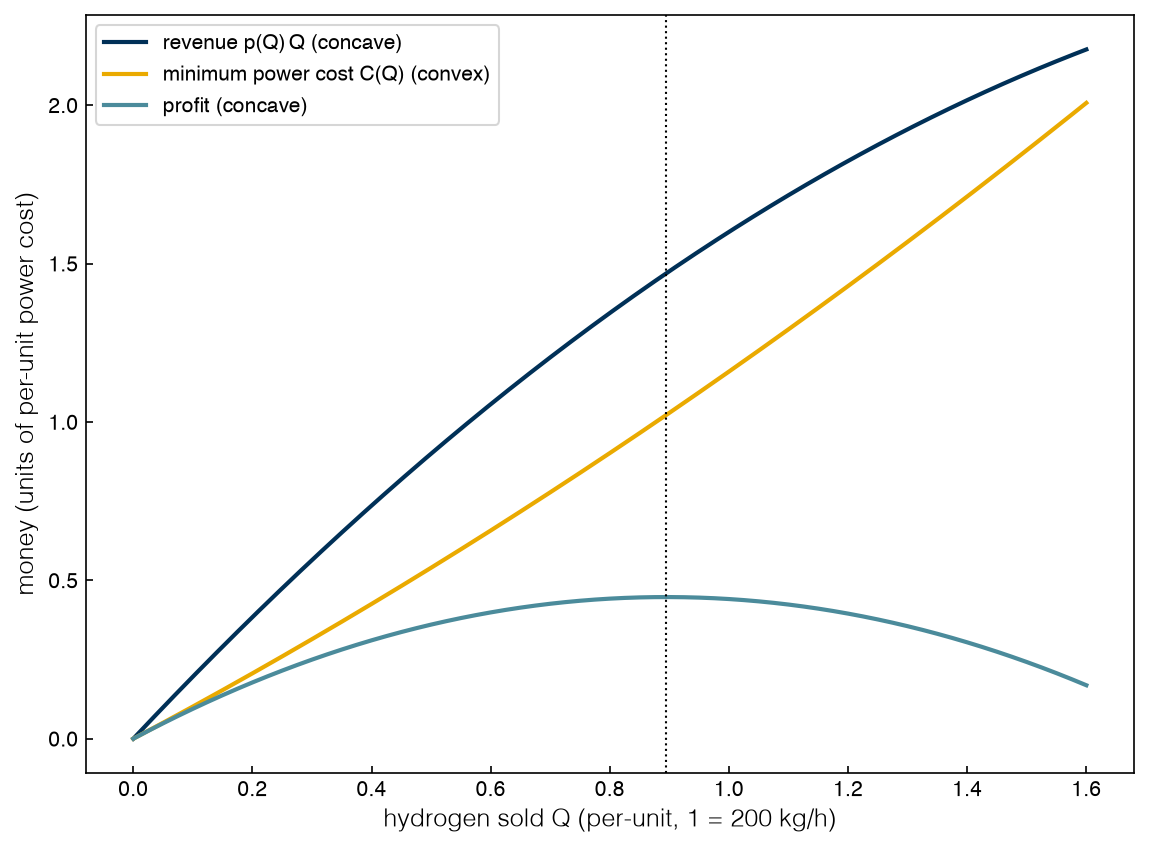

In [7]:
p0, s = 2.0, 0.4
S = np.sum(1 / (2 * rv))
Q = np.linspace(0, 1.6, 321)
C = np.array([t2.ohmic_dispatch(q)[2] for q in Q])   # exact minimum fleet power at each Q
revenue = (p0 - s * Q) * Q
profit = revenue - C
Q_star = (p0 - 1) / (2 * s + 1 / S)
lam_star, _, C_star, _ = t2.ohmic_dispatch(Q_star)
print(f"best quantity Q* = {Q_star:.4f} ({el.to_kg_h(Q_star):.0f} kg/h), "
      f"profit {Q_star * (p0 - s * Q_star) - C_star:.4f}")
print(f"marginal revenue {p0 - 2 * s * Q_star:.4f} = marginal cost {lam_star:.4f}")
print(f"largest second difference of the profit curve: {np.diff(profit, 2).max():.1e} (never positive: concave)")

fig, ax = plt.subplots()
ax.plot(Q, revenue, label='revenue $p(Q)\\,Q$ (concave)')
ax.plot(Q, C, label='minimum power cost $C(Q)$ (convex)')
ax.plot(Q, profit, label='profit (concave)')
ax.axvline(Q_star, color='k', ls=':', lw=1)
ax.set_xlabel('hydrogen sold $Q$ (per-unit, 1 = 200 kg/h)')
ax.set_ylabel('money (units of per-unit power cost)')
ax.legend();

| At the best quantity | Value |
|---|---|
| $Q^*$ (per-unit) | 0.8943 (179 kg/h) |
| Profit | 0.4472 |
| Marginal revenue | 1.2846 |
| Marginal cost | 1.2846 |

At the best quantity, the marginal revenue and marginal cost are the same. The profit curve is a dome with a single top, and a local solver will find the top from any starting point.

So non-convexity comes from the *shape* of a function rather than from nonlinearity. For the S-curve, the concave start-up term is what makes the Hessian indefinite at low load, and it is this term (rather than the quadratic) that will make the dispatch hard in {doc}`Topic2.6-Non-convex_Problems_and_Bounding`. Before choosing a solver it is a good idea to check convexity, either with the Hessian or with the composition rules above, since only on a convex problem can we trust a local solver's answer to be the global optimum.

:::{exercise}
:label: ex-t21-convex-rules

Use the composition rules (not the Hessian) to decide whether each function is convex on the domain given: (a) $f(x) = e^{x_1 + 2x_2}$ on $\mathbb{R}^2$; (b) the S-curve power $x + a x/(x+\epsilon) + r x^2$ on $x \ge 0$; (c) the profit $\Pi(Q)$ above, if the demand curve were $p(Q) = p_0 e^{-Q}$. For (c), plot $\Pi(Q)$ by editing the code above to check your answer.
:::

## Summary

- An NLP has continuous variables and at least one nonlinear function. Local solvers such as Ipopt are trustworthy on convex NLPs; non-convex NLPs need global solvers such as Couenne or BARON.
- With ohmic losses $P_i = x + r_i x^2$, the dispatch is a convex NLP whose optimum is in the interior: at $D = 1.2$ the loads are (0.3818, 0.5455, 0.2727) and the total power is 1.42909 per-unit (9.34 MW).
- The Hessian is the symmetric matrix of second derivatives; the signs of its eigenvalues classify it as definite, semidefinite or indefinite. The ideal-mixing Gibbs energy has a PSD Hessian whose zero eigenvector is the composition itself.
- A minimum needs a zero gradient and a PSD Hessian; a zero gradient with a positive definite Hessian proves a strict local minimum; a Hessian that is PSD everywhere proves convexity, and with it a global minimum.
- At the unconstrained optimum of the dispatch, the stacks' marginal powers are equal, $1 + 2 r_i x_i = \lambda = 1.38182$. That number becomes a Lagrange multiplier in Topic 2.2.
- Nonlinear is not non-convex. Concave revenue minus convex cost is still a convex problem; it is the concave start-up term of the S-curve that breaks convexity.

## Additional Reading

- L. T. Biegler, *Nonlinear Programming: Concepts, Algorithms, and Applications to Chemical Processes*, SIAM (2010), Chapter 2, on optimality conditions and convexity for unconstrained problems.
- J. Nocedal and S. J. Wright, *Numerical Optimization*, 2nd ed., Springer (2006), Chapter 2.
- A. Ravindran, K. M. Ragsdell and G. V. Reklaitis, *Engineering Optimization: Methods and Applications*, 2nd ed., Wiley (2006), on functions of several variables.
- S. Boyd and L. Vandenberghe, *Convex Optimization*, Cambridge University Press (2004), Chapter 3, on convex functions and the composition rules.
- M. L. Bynum, G. A. Hackebeil, W. E. Hart, C. D. Laird, B. L. Nicholson, J. D. Siirola, J.-P. Watson and D. L. Woodruff, *Pyomo — Optimization Modeling in Python*, 3rd ed., Springer (2021).